<a href="https://colab.research.google.com/github/radengustirangga-hub/UTS_DataMining/blob/main/wine_quality_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Kualitas Anggur (Wine Quality)

**Tujuan:** membangun model klasifikasi untuk memprediksi nilai `quality` anggur dari 11 fitur kimiawi, lalu memprediksi `data_testing.csv` dan menyimpan hasilnya dalam format `Id;Quality`.

**Alur kerja**
1. Persiapan data (load training & testing)
2. Pembersihan data (missing value, duplikat, outlier, skala fitur)
3. Pembuatan model (perbandingan beberapa model + tuning)
4. Evaluasi model (akurasi & confusion matrix)
5. Prediksi data uji & simpan model
6. Ekspor hasil prediksi (CSV)

## 1. Persiapan Data

Dataset diunduh dari https://bit.ly/datasetwine. Jalankan sel di bawah, lalu **upload** `data_training.csv` dan `data_testing.csv` jika file belum ada di Colab (atau mount Google Drive dan ubah path-nya).

In [37]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42

# --- ISI 3 digit terakhir NIM kamu ---
NIM3 = "013"
# Upload file jika belum ada (khusus Google Colab)
if not (os.path.exists('data_training.csv') and os.path.exists('data_testing.csv')):
    from google.colab import files
    print("Upload data_training.csv dan data_testing.csv")
    files.upload()

train = pd.read_csv('data_training.csv')
test = pd.read_csv('data_testing.csv')

print("Ukuran data training:", train.shape)
print("Ukuran data testing :", test.shape)
train.head()

Ukuran data training: (857, 13)
Ukuran data testing : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


**Interpretasi.** Data training berisi 12 kolom prediktor + target: 11 fitur kimiawi, kolom `quality` (target), dan kolom `Id` (hanya penanda baris). Data testing memiliki kolom yang sama **tanpa** `quality`. Kolom `Id` **tidak boleh dipakai sebagai fitur** karena hanya nomor identitas dan tidak membawa informasi kimiawi; kolom ini hanya dipakai untuk menandai hasil prediksi.

Fitur yang dipakai: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.261960,1.701992,4.60000,7.10000,7.90000,9.1000,15.6000
volatile acidity,857.0,0.529393,0.179162,0.12000,0.39500,0.52000,0.6400,1.5800
citric acid,857.0,0.267351,0.195144,0.00000,0.09000,0.25000,0.4200,1.0000
residual sugar,857.0,2.506184,1.293512,0.90000,1.90000,2.20000,2.6000,15.5000
chlorides,857.0,0.086830,0.048721,0.01200,0.07000,0.07900,0.0900,0.6110
free sulfur dioxide,857.0,15.782964,10.300402,1.00000,7.00000,14.00000,21.0000,68.0000
total sulfur dioxide,857.0,45.978413,31.692113,6.00000,21.00000,38.00000,63.0000,278.0000
density,857.0,0.996692,0.001901,0.99007,0.99552,0.99668,0.9978,1.0032
pH,857.0,3.313092,0.152079,2.74000,3.21000,3.31000,3.4000,4.0100
sulphates,857.0,0.656709,0.167364,0.39000,0.55000,0.62000,0.7300,2.0000



Distribusi target (quality):


,jumlah,persen
quality,,
3,6,0.7
4,26,3.0
5,362,42.2
6,341,39.8
7,109,12.7
8,13,1.5


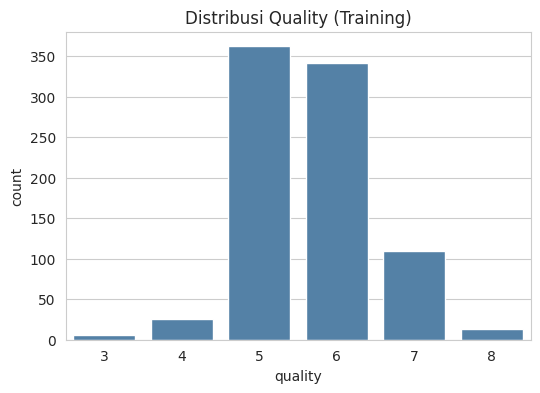

In [38]:
FEATURES = [c for c in train.columns if c not in ('quality', 'Id')]
print("Fitur yang dipakai:", FEATURES)

print("\nStatistik deskriptif:")
display(train[FEATURES + ['quality']].describe().T)

print("\nDistribusi target (quality):")
dist = train['quality'].value_counts().sort_index()
display(dist.to_frame('jumlah').assign(persen=lambda d: (d['jumlah'] / d['jumlah'].sum() * 100).round(1)))

plt.figure(figsize=(6, 4))
sns.countplot(x='quality', data=train, color='steelblue')
plt.title('Distribusi Quality (Training)')
plt.show()

**Interpretasi.** Target sangat **tidak seimbang**: sebagian besar sampel berada di kualitas 5 dan 6, sedangkan kualitas 3, 4, dan 8 sangat jarang (kelas 3 hanya 6 sampel). Akibatnya model cenderung bagus memprediksi kelas 5-6 dan lemah pada kelas ekstrem. Karena itu evaluasi tidak cukup dengan akurasi saja; confusion matrix perlu dilihat.

## 2. Pembersihan Data

### 2.1 Missing values

In [39]:
print("Missing values (training):", train.isna().sum().sum())
print("Missing values (testing) :", test.isna().sum().sum())
display(train.isna().sum().to_frame('missing').T)

Missing values (training): 0
Missing values (testing) : 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
missing,0,0,0,0,0,0,0,0,0,0,0,0,0


**Interpretasi.** Tidak ada nilai yang hilang pada data training maupun testing, sehingga **tidak perlu imputasi atau penghapusan baris**. (Untuk berjaga-jaga, pipeline model di bawah tetap memakai `SimpleImputer` median agar aman jika ada data kosong.)

### 2.2 Duplikat

In [40]:
dup = train[FEATURES + ['quality']].duplicated().sum()
print("Baris duplikat pada training (fitur + quality sama):", dup)
print("Id duplikat:", train['Id'].duplicated().sum())
print("Id training yang muncul juga di testing:", len(set(train['Id']) & set(test['Id'])))

Baris duplikat pada training (fitur + quality sama): 76
Id duplikat: 0
Id training yang muncul juga di testing: 0


**Interpretasi.** Ada sejumlah baris duplikat pada data training (sampel anggur dengan nilai kimia dan kualitas identik; hal ini umum pada dataset wine quality asli). Baris tersebut **dipertahankan** karena merupakan pengukuran yang sah, bukan kesalahan input, dan `Id` tidak ada yang bentrok antara training dan testing.

### 2.3 Outlier dan skala fitur (feature scaling)

,skewness
chlorides,6.090290
residual sugar,4.535850
sulphates,2.402228
total sulfur dioxide,1.463227
free sulfur dioxide,1.204074
fixed acidity,1.090374
alcohol,0.822848
volatile acidity,0.670264
citric acid,0.382388
pH,0.115650


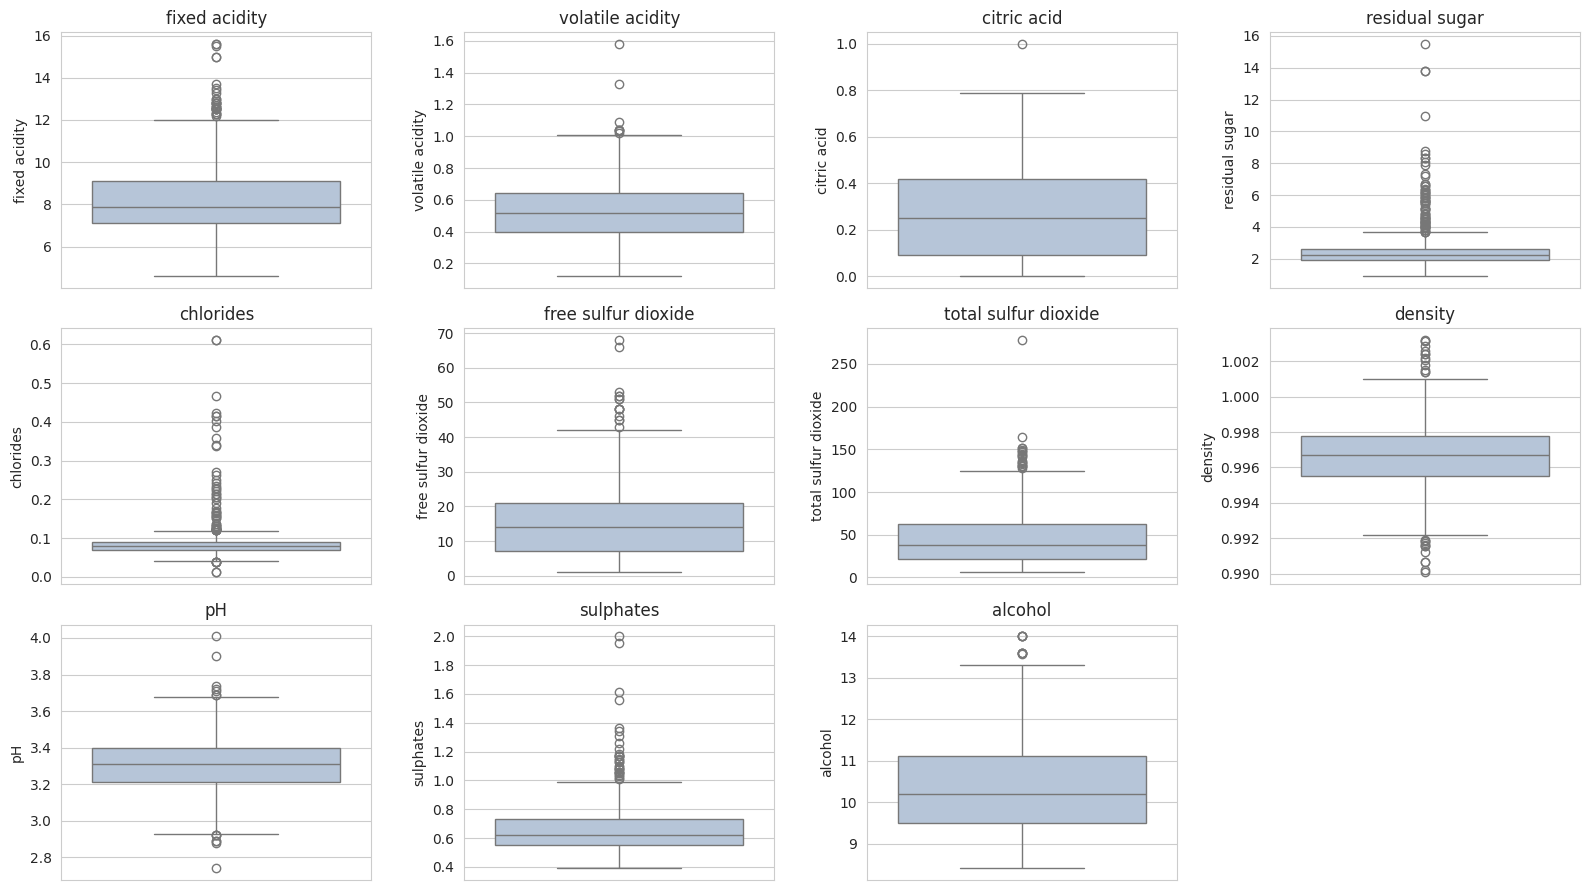

Rentang nilai tiap fitur (max - min):


,rentang
fixed acidity,11.000
volatile acidity,1.460
citric acid,1.000
residual sugar,14.600
chlorides,0.599
free sulfur dioxide,67.000
total sulfur dioxide,272.000
density,0.013
pH,1.270
sulphates,1.610


In [41]:
skew = train[FEATURES].skew().sort_values(ascending=False)
display(skew.to_frame('skewness'))

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=train[col], ax=ax, color='lightsteelblue')
    ax.set_title(col)
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

print("Rentang nilai tiap fitur (max - min):")
display((train[FEATURES].max() - train[FEATURES].min()).round(3).to_frame('rentang'))

**Interpretasi.**
- Beberapa fitur sangat menceng ke kanan (*skewed*), terutama `chlorides`, `sulphates`, dan `residual sugar`, dengan banyak outlier pada boxplot.
- Skala antarfitur sangat berbeda: `total sulfur dioxide` rentangnya ratusan, sedangkan `density` rentangnya hanya sekitar 0,01.
- **Keputusan:** outlier **tidak dihapus** karena kemungkinan besar adalah variasi alami anggur (dan data kecil, hanya 857 baris). Skala ulang (`StandardScaler`) **diterapkan hanya pada model yang sensitif jarak/skala** (Logistic Regression, KNN, SVM). Model berbasis pohon (Random Forest, Extra Trees, Gradient Boosting) **tidak memerlukan** scaling karena membelah data berdasarkan urutan nilai, bukan besarnya.

## 3. Pembuatan Model

Pertama, beberapa model kandidat dibandingkan memakai **Stratified 5-Fold Cross Validation** pada data training (stratified agar proporsi tiap kelas terjaga di setiap fold).

,Model,Akurasi CV (rata-rata),Std
0,Extra Trees,0.6488,0.0277
1,Random Forest,0.6418,0.0385
2,Gradient Boosting,0.6079,0.0137
3,SVM (RBF),0.6022,0.0405
4,Logistic Regression,0.5951,0.0451
5,KNN (k=15),0.5637,0.0385


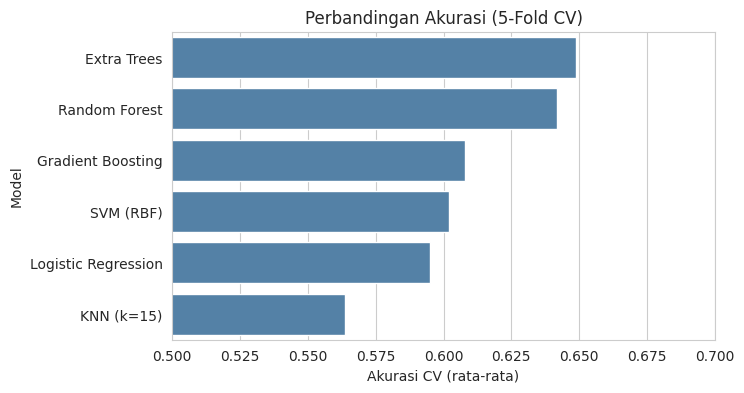

In [42]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

X = train[FEATURES]
y = train['quality']
X_test = test[FEATURES]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def scaled(model):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('clf', model)])

def unscaled(model):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('clf', model)])

kandidat = {
    'Logistic Regression': scaled(LogisticRegression(max_iter=2000)),
    'KNN (k=15)':          scaled(KNeighborsClassifier(n_neighbors=15)),
    'SVM (RBF)':           scaled(SVC(C=3)),
    'Gradient Boosting':   unscaled(GradientBoostingClassifier(random_state=RANDOM_STATE)),
    'Extra Trees':         unscaled(ExtraTreesClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)),
    'Random Forest':       unscaled(RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)),
}

hasil = []
for nama, model in kandidat.items():
    skor = cross_val_score(model, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
    hasil.append({'Model': nama, 'Akurasi CV (rata-rata)': skor.mean(), 'Std': skor.std()})

perbandingan = pd.DataFrame(hasil).sort_values('Akurasi CV (rata-rata)', ascending=False).reset_index(drop=True)
display(perbandingan.round(4))

plt.figure(figsize=(7, 4))
sns.barplot(data=perbandingan, y='Model', x='Akurasi CV (rata-rata)', color='steelblue')
plt.xlim(0.5, 0.7)
plt.title('Perbandingan Akurasi (5-Fold CV)')
plt.show()

**Interpretasi.** Model berbasis pohon yang di-*ensemble* (Random Forest dan Extra Trees) memberikan akurasi CV tertinggi (sekitar 64-65%), mengungguli model linear/jarak (sekitar 56-60%). Hal ini wajar: hubungan fitur kimiawi dengan kualitas tidak linear dan ada interaksi antarfitur (misalnya alkohol, sulphates, dan volatile acidity). Karena tugas ini 6 kelas dengan data yang kecil dan tidak seimbang, akurasi sekitar 65% termasuk wajar untuk dataset ini.

Selanjutnya **Random Forest** dituning dengan `GridSearchCV` (jumlah fitur per split, panjang daun minimal, dan pembobotan kelas).

In [43]:
param_grid = {
    'clf__max_features': ['sqrt', 0.5],
    'clf__min_samples_leaf': [1, 2],
    'clf__class_weight': [None, 'balanced_subsample'],
}

rf_pipe = unscaled(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=1, verbose=0)
grid.fit(X, y)

print("Parameter terbaik :", grid.best_params_)
print(f"Akurasi CV terbaik: {grid.best_score_:.4f}")

model_terbaik = grid.best_estimator_

Parameter terbaik : {'clf__class_weight': 'balanced_subsample', 'clf__max_features': 0.5, 'clf__min_samples_leaf': 1}
Akurasi CV terbaik: 0.6476


**Interpretasi.** `GridSearchCV` memilih kombinasi hiperparameter dengan akurasi CV tertinggi. Peningkatan dari model default biasanya kecil (sekitar 1 poin persen), yang menandakan bahwa batas performa lebih ditentukan oleh kualitas informasi pada fitur dan ketidakseimbangan kelas daripada oleh tuning.

## 4. Evaluasi Model pada Data Pelatihan

Evaluasi dilakukan dengan dua cara:
1. **Hold-out 20%** (data yang tidak dilihat model saat dilatih) untuk akurasi dan *classification report*.
2. **Prediksi cross-validation** pada seluruh data training untuk confusion matrix yang lebih stabil.

Akurasi hold-out 20%: 0.5988

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.66      0.77      0.71        73
           6       0.55      0.60      0.58        68
           7       0.45      0.23      0.30        22
           8       1.00      0.33      0.50         3

    accuracy                           0.60       172
   macro avg       0.44      0.32      0.35       172
weighted avg       0.57      0.60      0.58       172

Akurasi prediksi CV : 0.6476


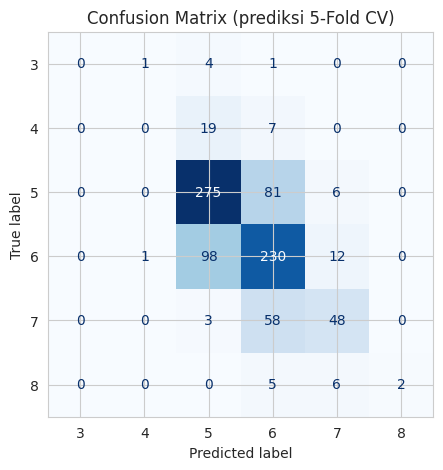

In [44]:
# 1) Hold-out 20%
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
m_holdout = grid.best_estimator_.fit(X_tr, y_tr)
pred_val = m_holdout.predict(X_val)

print(f"Akurasi hold-out 20%: {accuracy_score(y_val, pred_val):.4f}\n")
print(classification_report(y_val, pred_val, zero_division=0))

# 2) Confusion matrix dari prediksi CV (seluruh data training)
pred_cv = cross_val_predict(grid.best_estimator_, X, y, cv=cv, n_jobs=-1)
print(f"Akurasi prediksi CV : {accuracy_score(y, pred_cv):.4f}")

labels = sorted(y.unique())
cm = confusion_matrix(y, pred_cv, labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix (prediksi 5-Fold CV)')
plt.show()

**Interpretasi.**
- Akurasi hold-out 20% (sekitar 0,58) lebih rendah daripada akurasi CV (sekitar 0,65). Selisih ini wajar karena hold-out hanya berisi 172 sampel sehingga sangat berfluktuasi, dan model hold-out dilatih dengan data lebih sedikit. Estimasi CV (rata-rata 5 lipatan) lebih stabil, jadi performa sebenarnya diperkirakan di kisaran 0,58-0,65.
- Pada confusion matrix, prediksi benar terkonsentrasi pada kelas **5** dan **6**, dan kesalahan umumnya hanya meleset **satu tingkat** (5 vs 6, 6 vs 7). Ini wajar karena batas antar kualitas bersebelahan sangat tipis.
- Kelas langka (3 dan 4) tidak pernah terprediksi benar, dan kelas 8 hanya sedikit; ini keterbatasan akibat jumlah sampel yang sangat sedikit.

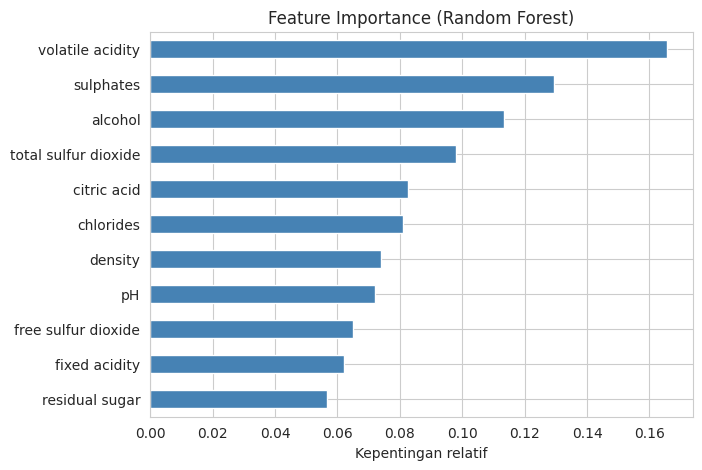

In [45]:
# Fitur yang paling berpengaruh
rf = model_terbaik.named_steps['clf']
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(7, 5))
imp.plot(kind='barh', color='steelblue')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Kepentingan relatif')
plt.show()

**Interpretasi.** Fitur yang paling berpengaruh terhadap prediksi adalah **volatile acidity**, **alcohol**, dan **sulphates**, diikuti **total sulfur dioxide** dan **chlorides**. Hal ini selaras dengan pengetahuan domain: volatile acidity tinggi (rasa seperti cuka) menurunkan kualitas, sedangkan alkohol yang lebih tinggi dan sulphates yang memadai cenderung berkaitan dengan kualitas lebih baik. Catatan: feature importance Random Forest menunjukkan besarnya pengaruh, bukan arah hubungannya.

## 5. Prediksi Data Uji dan Penyimpanan Model

Model final dilatih ulang pada **seluruh data training** (setelah hiperparameter ditentukan), disimpan dengan `joblib`, lalu dipakai memprediksi `data_testing.csv` (deployment pada data testing).

In [46]:
# Latih ulang model final pada seluruh data training
model_final = grid.best_estimator_.fit(X, y)

joblib.dump(model_final, 'model_wine_quality.joblib')
print("Model tersimpan: model_wine_quality.joblib")

model_dimuat = joblib.load('model_wine_quality.joblib')
pred_test = model_dimuat.predict(X_test)

print("Jumlah prediksi:", len(pred_test))
print("Distribusi prediksi:")
display(pd.Series(pred_test).value_counts().sort_index().to_frame('jumlah'))

Model tersimpan: model_wine_quality.joblib
Jumlah prediksi: 286
Distribusi prediksi:


,jumlah
5,132
6,127
7,25
8,2


**Interpretasi.** Distribusi prediksi pada data testing mengikuti pola data training (terkonsentrasi pada kualitas 5 dan 6), menunjukkan model konsisten dengan pola data latih.

## 6. Ekspor Hasil Prediksi

Sesuai ketentuan, file hanya berisi dua kolom: `Id` dan `Quality`, dengan pemisah titik koma (`;`) seperti pada `hasilprediksi_3digitNIMterakhir.csv`. Nama file diganti dengan 3 digit NIM terakhir (isi `NIM3` di sel pertama).

In [47]:
submission = pd.DataFrame({'Id': test['Id'].astype(int), 'Quality': pred_test.astype(int)})

# Validasi format
assert list(submission.columns) == ['Id', 'Quality']
assert len(submission) == len(test)
assert submission['Id'].is_unique
assert submission['Quality'].isna().sum() == 0

nama_file = f'hasilprediksi_{NIM3}.csv'
submission.to_csv(nama_file, sep=';', index=False)
print("Tersimpan:", nama_file)
print(open(nama_file).read()[:150])
submission.head()

Tersimpan: hasilprediksi_013.csv
Id;Quality
222;5
1514;6
417;5
754;5
516;6
1120;6
180;5
82;5
632;6
592;5
501;7
1586;7
1096;6
1101;6
1488;5
700;5
631;6
1022;5
1420;5
882;7
1170;8
911;6


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6


In [48]:
try:
    from google.colab import files
    files.download(nama_file)
    files.download('model_wine_quality.joblib')
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kesimpulan

- Data bersih: tidak ada missing value; outlier dipertahankan; scaling hanya untuk model berbasis jarak/linear.
- Model terbaik: **Random Forest** (dituning dengan GridSearchCV) dengan akurasi CV sekitar 65% (hold-out sekitar 58%).
- Fitur paling berpengaruh: volatile acidity, alcohol, sulphates.
- Keterbatasan: kelas kualitas ekstrem (3, 4, 8) sangat sedikit sehingga sulit diprediksi; perbaikan bisa dicoba dengan teknik penyeimbangan kelas (SMOTE) atau pengelompokan kualitas.